In [4]:
%pip install seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Make plots look a bit nicer
sns.set(style="whitegrid")

print("Libraries imported successfully")

Note: you may need to restart the kernel to use updated packages.
Libraries imported successfully


In [5]:
# Column names based on german.doc
column_names = [
    "checking_status",      # Attribute 1
    "duration_months",      # Attribute 2
    "credit_history",       # Attribute 3
    "purpose",              # Attribute 4
    "credit_amount",        # Attribute 5
    "savings",              # Attribute 6
    "employment_since",     # Attribute 7
    "installment_rate",     # Attribute 8
    "personal_status_sex",  # Attribute 9
    "other_debtors",        # Attribute 10
    "residence_since",      # Attribute 11
    "property",             # Attribute 12
    "age",                  # Attribute 13
    "other_installment",    # Attribute 14
    "housing",              # Attribute 15
    "existing_credits",     # Attribute 16
    "job",                  # Attribute 17
    "people_liable",        # Attribute 18
    "telephone",            # Attribute 19
    "foreign_worker",       # Attribute 20
    "target"                # 1 = Good, 2 = Bad
]

# Load the file (space separated, no header)
df = pd.read_csv("/Users/vedbhatt/Desktop/Responsible_AI/RAI_project/statlog+german+credit+data/german.data", sep=" ", header=None, names=column_names)

print("Data loaded")
print("Shape:", df.shape)

Data loaded
Shape: (1000, 21)


In [6]:
# First 5 rows
print("First 5 rows:")
display(df.head())

# Data types
print("\nData types:")
print(df.dtypes)

# Missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Quick summary of numeric columns
print("\nSummary of numeric columns:")
display(df.describe())

First 5 rows:


,checking_status,duration_months,credit_history,purpose,credit_amount,savings,employment_since,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment,housing,existing_credits,job,people_liable,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2



Data types:
checking_status        object
duration_months         int64
credit_history         object
purpose                object
credit_amount           int64
savings                object
employment_since       object
installment_rate        int64
personal_status_sex    object
other_debtors          object
residence_since         int64
property               object
age                     int64
other_installment      object
housing                object
existing_credits        int64
job                    object
people_liable           int64
telephone              object
foreign_worker         object
target                  int64
dtype: object

Missing values per column:
checking_status        0
duration_months        0
credit_history         0
purpose                0
credit_amount          0
savings                0
employment_since       0
installment_rate       0
personal_status_sex    0
other_debtors          0
residence_since        0
property               0
age            

,duration_months,credit_amount,installment_rate,residence_since,age,existing_credits,people_liable,target
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000,1.300000
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086,0.458487
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000,1.000000
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000,1.000000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000,1.000000
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000,2.000000
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000,2.000000


target
1    700
2    300
Name: count, dtype: int64


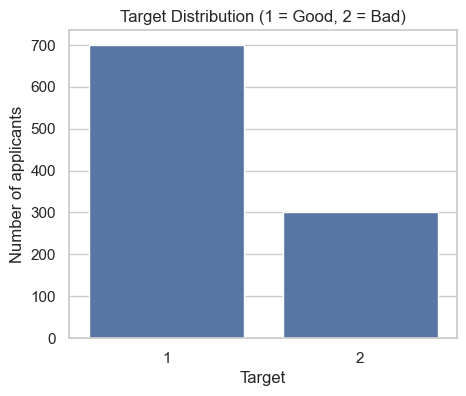

In [7]:
# Count of each target value
print(df["target"].value_counts())

plt.figure(figsize=(5, 4))
sns.countplot(x="target", data=df)
plt.title("Target Distribution (1 = Good, 2 = Bad)")
plt.xlabel("Target")
plt.ylabel("Number of applicants")
plt.show()

In [8]:
# Original: 1 = Good, 2 = Bad
# New: 0 = Good, 1 = Bad
df["bad_credit"] = df["target"].map({1: 0, 2: 1})

# Check the conversion
print(pd.crosstab(df["target"], df["bad_credit"]))
print("\nCounts:")
print(df["bad_credit"].value_counts())

bad_credit    0    1
target              
1           700    0
2             0  300

Counts:
bad_credit
0    700
1    300
Name: count, dtype: int64


In [9]:
# Binary age group: 0 = under 35, 1 = 35 and above
df["age_group"] = np.where(df["age"] < 35, "<35", ">=35")

# Check age range and the new column
print("Age range:", df["age"].min(), "to", df["age"].max())
print()
display(df[["age", "age_group"]].head(10))

Age range: 19 to 75



,age,age_group
0,67,>=35
1,22,<35
2,49,>=35
3,45,>=35
4,53,>=35
5,35,>=35
6,53,>=35
7,35,>=35
8,61,>=35
9,28,<35


In [10]:
# Group sizes
group_counts = df["age_group"].value_counts()
group_percent = df["age_group"].value_counts(normalize=True) * 100

print("Group sizes:")
print(group_counts)
print("\nGroup percentages:")
print(group_percent.round(1))

# Bad-credit rate in each age group
bad_rate = df.groupby("age_group")["bad_credit"].agg(["count", "sum", "mean"])
bad_rate.columns = ["total_applicants", "bad_credits", "bad_rate"]
bad_rate["bad_rate"] = (bad_rate["bad_rate"] * 100).round(1)

print("\nBad-credit rate by age group:")
display(bad_rate)

Group sizes:
age_group
<35     548
>=35    452
Name: count, dtype: int64

Group percentages:
age_group
<35     54.8
>=35    45.2
Name: proportion, dtype: float64

Bad-credit rate by age group:


,total_applicants,bad_credits,bad_rate
age_group,,,
<35,548,192,35.0
>=35,452,108,23.9


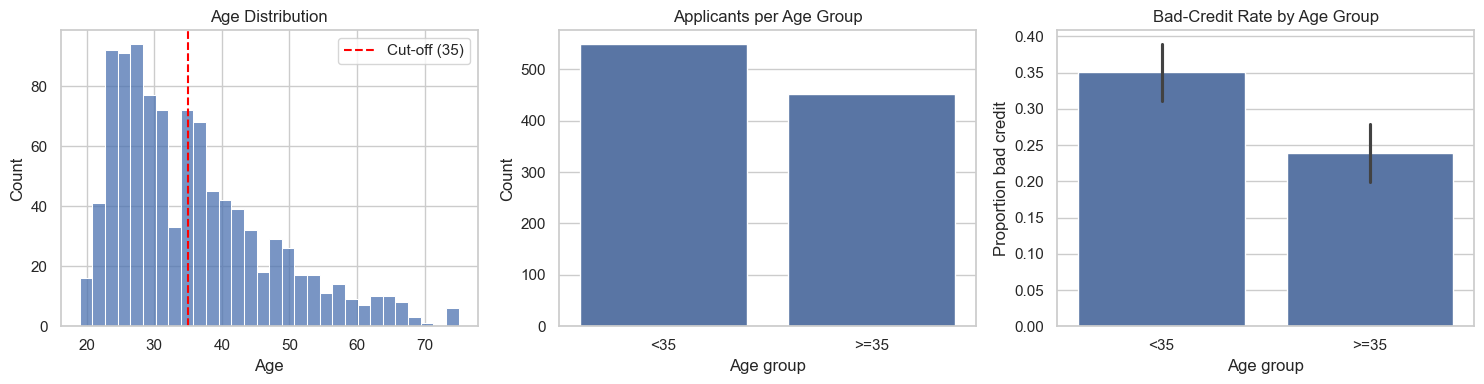

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Plot 1: age distribution with the cut-off line
sns.histplot(df["age"], bins=30, ax=axes[0])
axes[0].axvline(35, color="red", linestyle="--", label="Cut-off (35)")
axes[0].set_title("Age Distribution")
axes[0].set_xlabel("Age")
axes[0].legend()

# Plot 2: number of applicants per age group
sns.countplot(x="age_group", data=df, order=["<35", ">=35"], ax=axes[1])
axes[1].set_title("Applicants per Age Group")
axes[1].set_xlabel("Age group")
axes[1].set_ylabel("Count")

# Plot 3: bad-credit rate per age group
sns.barplot(x="age_group", y="bad_credit", data=df, order=["<35", ">=35"], ax=axes[2])
axes[2].set_title("Bad-Credit Rate by Age Group")
axes[2].set_xlabel("Age group")
axes[2].set_ylabel("Proportion bad credit")

plt.tight_layout()
plt.show()

In [12]:
# Columns we will NOT use as model inputs
label_columns = ["target", "bad_credit"]
sensitive_columns = ["age", "age_group"]   # only age is excluded

# Numeric features (age is left out because it is sensitive)
numeric_features = [
    "duration_months",
    "credit_amount",
    "installment_rate",
    "residence_since",
    "existing_credits",
    "people_liable"
]

# Categorical features = everything that is left over
categorical_features = [
    col for col in df.columns
    if col not in label_columns + sensitive_columns + numeric_features
]

print("Numeric features:", numeric_features)
print()
print("Categorical features:", categorical_features)
print()
print("Total features:", len(numeric_features) + len(categorical_features))

Numeric features: ['duration_months', 'credit_amount', 'installment_rate', 'residence_since', 'existing_credits', 'people_liable']

Categorical features: ['checking_status', 'credit_history', 'purpose', 'savings', 'employment_since', 'personal_status_sex', 'other_debtors', 'property', 'other_installment', 'housing', 'job', 'telephone', 'foreign_worker']

Total features: 19


In [13]:
X = df[numeric_features + categorical_features]
y = df["bad_credit"]

# Kept aside only for auditing fairness (NOT used for training)
age_group = df["age_group"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print()
display(X.head())

X shape: (1000, 19)
y shape: (1000,)



,duration_months,credit_amount,installment_rate,residence_since,existing_credits,people_liable,checking_status,credit_history,purpose,savings,employment_since,personal_status_sex,other_debtors,property,other_installment,housing,job,telephone,foreign_worker
0,6,1169,4,4,2,1,A11,A34,A43,A65,A75,A93,A101,A121,A143,A152,A173,A192,A201
1,48,5951,2,2,1,1,A12,A32,A43,A61,A73,A92,A101,A121,A143,A152,A173,A191,A201
2,12,2096,2,3,1,2,A14,A34,A46,A61,A74,A93,A101,A121,A143,A152,A172,A191,A201
3,42,7882,2,4,1,2,A11,A32,A42,A61,A74,A93,A103,A122,A143,A153,A173,A191,A201
4,24,4870,3,4,2,2,A11,A33,A40,A61,A73,A93,A101,A124,A143,A153,A173,A191,A201


In [14]:
print("Is 'age' in X?                ", "age" in X.columns)
print("Is 'age_group' in X?          ", "age_group" in X.columns)
print("Is 'personal_status_sex' in X?", "personal_status_sex" in X.columns)
print("Is 'bad_credit' in X?         ", "bad_credit" in X.columns)
print("Is 'target' in X?             ", "target" in X.columns)

Is 'age' in X?                 False
Is 'age_group' in X?           False
Is 'personal_status_sex' in X? True
Is 'bad_credit' in X?          False
Is 'target' in X?              False


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print(preprocessor)

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['duration_months', 'credit_amount',
                                  'installment_rate', 'residence_since',
                                  'existing_credits', 'people_liable']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['checking_status', 'credit_history',
                                  'purpose', 'savings', 'employment_since',
                                  'personal_status_sex', 'other_debtors',
                                  'property', 'other_installment', 'housing',
                                  'job', 'telephone', 'foreign_worker'])])


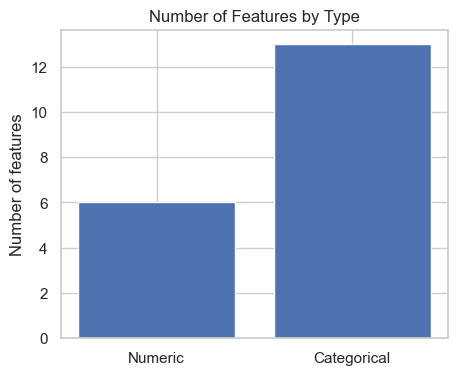

In [16]:
plt.figure(figsize=(5, 4))
plt.bar(["Numeric", "Categorical"], [len(numeric_features), len(categorical_features)])
plt.title("Number of Features by Type")
plt.ylabel("Number of features")
plt.show()

In [17]:
# Combine target and age group, e.g. "0_<35", "1_>=35"
strat_label = y.astype(str) + "_" + age_group

print(strat_label.value_counts())

0_<35     356
0_>=35    344
1_<35     192
1_>=35    108
Name: count, dtype: int64


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp, age_train, age_temp, strat_train, strat_temp = train_test_split(
    X, y, age_group, strat_label,
    test_size=0.20,
    stratify=strat_label,
    random_state=42
)

print("Train size:", X_train.shape[0])
print("Temp size: ", X_temp.shape[0])

Train size: 800
Temp size:  200


In [19]:
X_val, X_test, y_val, y_test, age_val, age_test = train_test_split(
    X_temp, y_temp, age_temp,
    test_size=0.50,
    stratify=strat_temp,
    random_state=42
)

print("Train:     ", X_train.shape[0])
print("Validation:", X_val.shape[0])
print("Test:      ", X_test.shape[0])

Train:      800
Validation: 100
Test:       100


In [20]:
# Bad-credit rate in each set
print("Bad-credit rate (%):")
print("Train:     ", round(y_train.mean() * 100, 1))
print("Validation:", round(y_val.mean() * 100, 1))
print("Test:      ", round(y_test.mean() * 100, 1))

# Age-group counts in each set
split_summary = pd.DataFrame({
    "Train": age_train.value_counts(),
    "Validation": age_val.value_counts(),
    "Test": age_test.value_counts()
})
print("\nAge-group counts per set:")
display(split_summary)

# Bad-credit counts per age group in each set
bad_counts = pd.DataFrame({
    "Train": y_train.groupby(age_train).sum(),
    "Validation": y_val.groupby(age_val).sum(),
    "Test": y_test.groupby(age_test).sum()
})
print("\nNumber of bad credits per age group in each set:")
display(bad_counts)

Bad-credit rate (%):
Train:      30.0
Validation: 30.0
Test:       30.0

Age-group counts per set:


,Train,Validation,Test
age_group,,,
<35,439,54,55
>=35,361,46,45



Number of bad credits per age group in each set:


,Train,Validation,Test
age_group,,,
<35,154,19,19
>=35,86,11,11


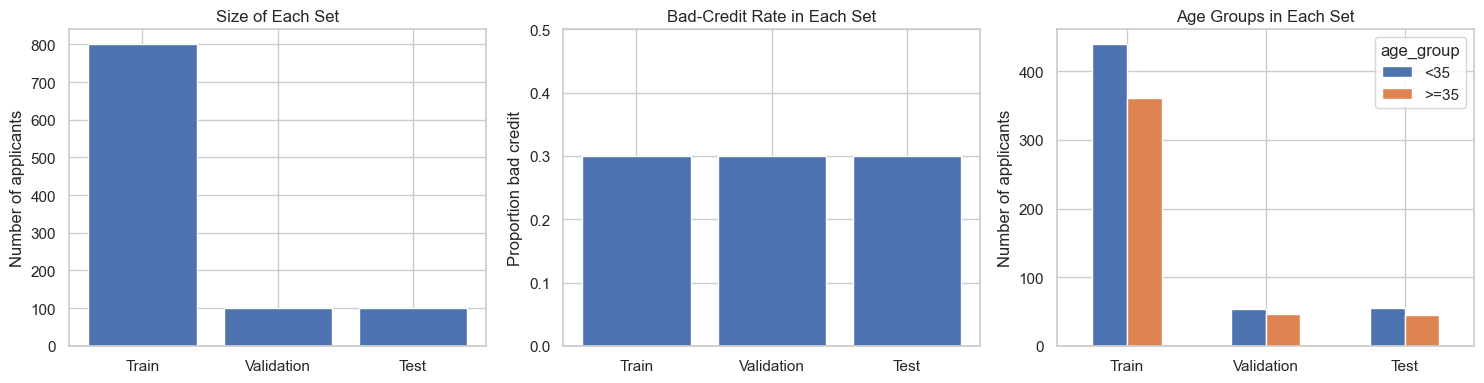

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Plot 1: size of each set
axes[0].bar(["Train", "Validation", "Test"], [len(X_train), len(X_val), len(X_test)])
axes[0].set_title("Size of Each Set")
axes[0].set_ylabel("Number of applicants")

# Plot 2: bad-credit rate in each set
axes[1].bar(["Train", "Validation", "Test"], [y_train.mean(), y_val.mean(), y_test.mean()])
axes[1].set_title("Bad-Credit Rate in Each Set")
axes[1].set_ylabel("Proportion bad credit")
axes[1].set_ylim(0, 0.5)

# Plot 3: age-group counts in each set
split_summary.T.plot(kind="bar", ax=axes[2])
axes[2].set_title("Age Groups in Each Set")
axes[2].set_ylabel("Number of applicants")
axes[2].set_xticklabels(["Train", "Validation", "Test"], rotation=0)

plt.tight_layout()
plt.show()

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

print(baseline_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['duration_months',
                                                   'credit_amount',
                                                   'installment_rate',
                                                   'residence_since',
                                                   'existing_credits',
                                                   'people_liable']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['checking_status',
                                                   'credit_history', 'purpose',
                                                   'savings',
                                                   'employment_since',
                                          

In [23]:
baseline_model.fit(X_train, y_train)

print("Baseline model trained on", X_train.shape[0], "training rows")

Baseline model trained on 800 training rows


In [24]:
# Column 1 = probability of class 1 (bad credit)
val_probs = baseline_model.predict_proba(X_val)[:, 1]

print("First 10 predicted probabilities of bad credit:")
print(val_probs[:10].round(3))
print()
print("Min probability: ", val_probs.min().round(3))
print("Max probability: ", val_probs.max().round(3))
print("Mean probability:", val_probs.mean().round(3))

First 10 predicted probabilities of bad credit:
[0.018 0.129 0.044 0.648 0.436 0.504 0.481 0.032 0.081 0.55 ]

Min probability:  0.008
Max probability:  0.954
Mean probability: 0.344


In [25]:
from sklearn.metrics import accuracy_score, roc_auc_score

val_pred_default = (val_probs >= 0.5).astype(int)

print("Validation accuracy (threshold 0.5):", round(accuracy_score(y_val, val_pred_default), 3))
print("Validation ROC-AUC:                 ", round(roc_auc_score(y_val, val_probs), 3))

Validation accuracy (threshold 0.5): 0.72
Validation ROC-AUC:                  0.748


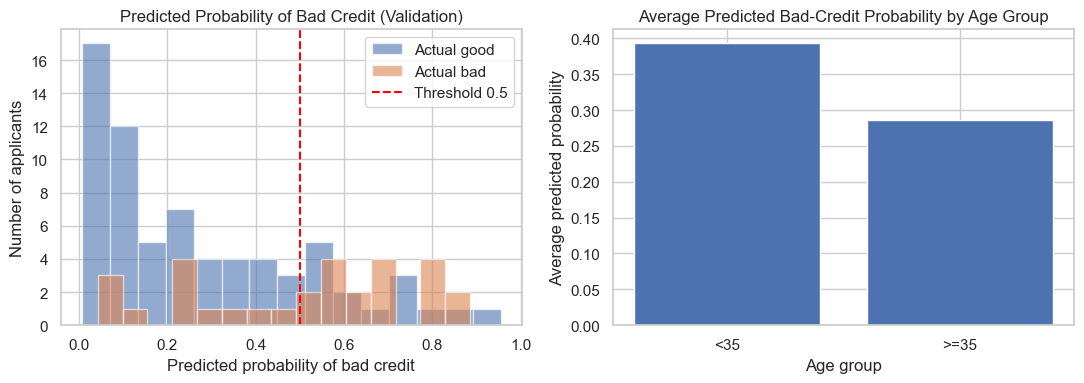

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Plot 1: histogram of predicted probabilities, split by true label
axes[0].hist(val_probs[y_val == 0], bins=15, alpha=0.6, label="Actual good")
axes[0].hist(val_probs[y_val == 1], bins=15, alpha=0.6, label="Actual bad")
axes[0].axvline(0.5, color="red", linestyle="--", label="Threshold 0.5")
axes[0].set_title("Predicted Probability of Bad Credit (Validation)")
axes[0].set_xlabel("Predicted probability of bad credit")
axes[0].set_ylabel("Number of applicants")
axes[0].legend()

# Plot 2: average predicted probability by age group
avg_by_group = pd.Series(val_probs, index=y_val.index).groupby(age_val).mean()
axes[1].bar(avg_by_group.index, avg_by_group.values)
axes[1].set_title("Average Predicted Bad-Credit Probability by Age Group")
axes[1].set_xlabel("Age group")
axes[1].set_ylabel("Average predicted probability")

plt.tight_layout()
plt.show()

In [27]:
import joblib

joblib.dump(baseline_model, "baseline_model.joblib")

print("Model saved as baseline_model.joblib")

Model saved as baseline_model.joblib


In [28]:
loaded_model = joblib.load("baseline_model.joblib")

# The loaded model should give identical probabilities
loaded_probs = loaded_model.predict_proba(X_val)[:, 1]

print("Probabilities identical:", np.allclose(val_probs, loaded_probs))

Probabilities identical: True


In [29]:
X_test.to_csv("X_test.csv", index=False)
y_test.to_csv("y_test.csv", index=False)
age_test.to_csv("age_test.csv", index=False)

In [30]:
from sklearn.metrics import confusion_matrix

def total_cost(y_true, y_pred):
    # tn = good predicted good, fp = good predicted bad,
    # fn = bad predicted good, tp = bad predicted bad
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    cost = (5 * fn) + (1 * fp)
    return cost

# Quick check with the default 0.5 threshold from Step 5
default_cost = total_cost(y_val, val_pred_default)
print("Validation cost at threshold 0.5:", default_cost)

Validation cost at threshold 0.5: 80


In [31]:
thresholds = np.arange(0.05, 0.95, 0.01)
costs = []

for t in thresholds:
    preds = (val_probs >= t).astype(int)
    costs.append(total_cost(y_val, preds))

threshold_table = pd.DataFrame({"threshold": thresholds.round(2), "cost": costs})

print("Lowest 10 costs:")
display(threshold_table.sort_values("cost").head(10))

Lowest 10 costs:


,threshold,cost
16,0.21,55
15,0.20,56
14,0.19,56
13,0.18,57
12,0.17,57
2,0.07,58
11,0.16,58
10,0.15,58
17,0.22,59
1,0.06,59


In [32]:
# Threshold with the lowest validation cost
best_idx = np.argmin(costs)
best_threshold = round(thresholds[best_idx], 2)
best_cost = costs[best_idx]

# Theoretical threshold: predict bad if P(bad) > 1/6
theory_threshold = 1 / 6

print("Best threshold (validation):", best_threshold)
print("Cost at best threshold:     ", best_cost)
print("Cost at threshold 0.5:      ", default_cost)
print("Theoretical threshold (1/6):", round(theory_threshold, 3))

Best threshold (validation): 0.21
Cost at best threshold:      55
Cost at threshold 0.5:       80
Theoretical threshold (1/6): 0.167


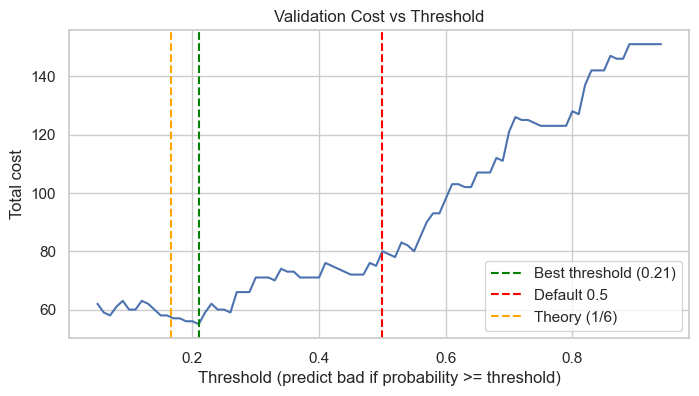

In [33]:
plt.figure(figsize=(8, 4))
plt.plot(thresholds, costs)
plt.axvline(best_threshold, color="green", linestyle="--", label=f"Best threshold ({best_threshold})")
plt.axvline(0.5, color="red", linestyle="--", label="Default 0.5")
plt.axvline(theory_threshold, color="orange", linestyle="--", label="Theory (1/6)")
plt.title("Validation Cost vs Threshold")
plt.xlabel("Threshold (predict bad if probability >= threshold)")
plt.ylabel("Total cost")
plt.legend()
plt.show()

In [34]:
val_pred_best = (val_probs >= best_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_val, val_pred_best).ravel()
tn0, fp0, fn0, tp0 = confusion_matrix(y_val, val_pred_default).ravel()

compare = pd.DataFrame({
    "Threshold 0.5": [tn0, fp0, fn0, tp0, fn0 * 5 + fp0],
    f"Threshold {best_threshold}": [tn, fp, fn, tp, fn * 5 + fp]
}, index=["Good approved (TN)", "Good denied (FP)", "Bad approved (FN)", "Bad denied (TP)", "Total cost"])

display(compare)

,Threshold 0.5,Threshold 0.21
Good approved (TN),55,35
Good denied (FP),15,35
Bad approved (FN),13,4
Bad denied (TP),17,26
Total cost,80,55


In [35]:
balanced_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])
balanced_model.fit(X_train, y_train)
balanced_probs = balanced_model.predict_proba(X_val)[:, 1]

balanced_costs = []
for t in thresholds:
    preds = (balanced_probs >= t).astype(int)
    balanced_costs.append(total_cost(y_val, preds))

best_bal_idx = np.argmin(balanced_costs)
print("Baseline (no class weight):  best cost =", best_cost, "at threshold", best_threshold)
print("Balanced class weight:       best cost =", balanced_costs[best_bal_idx],
      "at threshold", round(thresholds[best_bal_idx], 2))

Baseline (no class weight):  best cost = 55 at threshold 0.21
Balanced class weight:       best cost = 56 at threshold 0.25


In [36]:
joblib.dump(best_threshold, "baseline_threshold.joblib")
print("Saved threshold:", best_threshold)

Saved threshold: 0.21


In [37]:
# Load the saved threshold (same one we chose on validation)
threshold = joblib.load("baseline_threshold.joblib")
print("Using threshold:", threshold)

# Probabilities of bad credit, then decisions
test_probs = baseline_model.predict_proba(X_test)[:, 1]
test_pred = (test_probs >= threshold).astype(int)

print("Test rows:", len(test_pred))
print("Predicted bad (denied):", test_pred.sum())
print("Predicted good (approved):", len(test_pred) - test_pred.sum())

Using threshold: 0.21
Test rows: 100
Predicted bad (denied): 48
Predicted good (approved): 52


In [38]:
from sklearn.metrics import precision_score, recall_score, f1_score

tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (bad)", "Recall (bad)", "F1 (bad)", "ROC-AUC", "Total cost"],
    "Value": [
        round(accuracy_score(y_test, test_pred), 3),
        round(precision_score(y_test, test_pred), 3),
        round(recall_score(y_test, test_pred), 3),
        round(f1_score(y_test, test_pred), 3),
        round(roc_auc_score(y_test, test_probs), 3),
        fn * 5 + fp
    ]
})

print("Test-set results at threshold", threshold)
display(results)

print("Confusion matrix counts:")
print("Good approved (TN):", tn)
print("Good denied (FP):  ", fp)
print("Bad approved (FN): ", fn)
print("Bad denied (TP):   ", tp)

Test-set results at threshold 0.21


,Metric,Value
0,Accuracy,0.700
1,Precision (bad),0.500
2,Recall (bad),0.800
3,F1 (bad),0.615
4,ROC-AUC,0.794
5,Total cost,54.000


Confusion matrix counts:
Good approved (TN): 46
Good denied (FP):   24
Bad approved (FN):  6
Bad denied (TP):    24


In [39]:
# Rule 1: approve everyone (predict 0 for all)
approve_all = np.zeros(len(y_test), dtype=int)
# Rule 2: deny everyone (predict 1 for all)
deny_all = np.ones(len(y_test), dtype=int)
# Model at the default 0.5 threshold
model_default = (test_probs >= 0.5).astype(int)

cost_table = pd.DataFrame({
    "Rule": ["Approve everyone", "Deny everyone", "Model at 0.5", f"Model at {threshold}"],
    "Total cost": [
        total_cost(y_test, approve_all),
        total_cost(y_test, deny_all),
        total_cost(y_test, model_default),
        total_cost(y_test, test_pred)
    ]
})

display(cost_table)

,Rule,Total cost
0,Approve everyone,150
1,Deny everyone,70
2,Model at 0.5,91
3,Model at 0.21,54


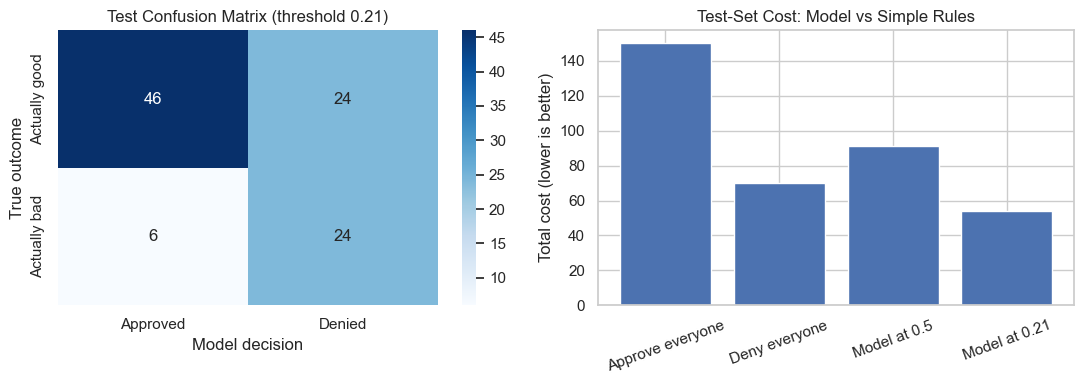

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Plot 1: confusion matrix
cm = confusion_matrix(y_test, test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Approved", "Denied"],
            yticklabels=["Actually good", "Actually bad"])
axes[0].set_title(f"Test Confusion Matrix (threshold {threshold})")
axes[0].set_xlabel("Model decision")
axes[0].set_ylabel("True outcome")

# Plot 2: cost comparison
axes[1].bar(cost_table["Rule"], cost_table["Total cost"])
axes[1].set_title("Test-Set Cost: Model vs Simple Rules")
axes[1].set_ylabel("Total cost (lower is better)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [41]:
import joblib
import os

# Make a folder for saved files
os.makedirs("saved_files", exist_ok=True)

# 1. The trained baseline model (includes preprocessing)
joblib.dump(baseline_model, "saved_files/baseline_model.joblib")

# 2. The chosen threshold
joblib.dump(best_threshold, "saved_files/baseline_threshold.joblib")

# 3. All data splits (joblib keeps the row indexes, which we need for alignment)
splits = {
    "X_train": X_train, "X_val": X_val, "X_test": X_test,
    "y_train": y_train, "y_val": y_val, "y_test": y_test,
    "age_train": age_train, "age_val": age_val, "age_test": age_test,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features
}
joblib.dump(splits, "saved_files/splits.joblib")

# 4. The full dataframe (useful for later steps such as personal status analysis)
df.to_pickle("saved_files/df.pkl")

print("Saved files:")
print(os.listdir("saved_files"))

Saved files:
['baseline_model.joblib', 'df.pkl', 'splits.joblib', 'baseline_threshold.joblib']


In [42]:
# ---------- Restore session ----------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, roc_auc_score,
                             precision_score, recall_score, f1_score)

sns.set(style="whitegrid")

# Load model, threshold, data
baseline_model = joblib.load("saved_files/baseline_model.joblib")
best_threshold = joblib.load("saved_files/baseline_threshold.joblib")
threshold = best_threshold
splits = joblib.load("saved_files/splits.joblib")
df = pd.read_pickle("saved_files/df.pkl")

# Unpack the splits into the same variable names used before
X_train, X_val, X_test = splits["X_train"], splits["X_val"], splits["X_test"]
y_train, y_val, y_test = splits["y_train"], splits["y_val"], splits["y_test"]
age_train, age_val, age_test = splits["age_train"], splits["age_val"], splits["age_test"]
numeric_features = splits["numeric_features"]
categorical_features = splits["categorical_features"]

# Re-define the cost function (functions are not saved in files)
def total_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return (5 * fn) + (1 * fp)

# Quick check that everything came back correctly
val_probs = baseline_model.predict_proba(X_val)[:, 1]
print("Train / Val / Test sizes:", len(X_train), len(X_val), len(X_test))
print("Threshold:", threshold)
print("Validation ROC-AUC (should be 0.748):", round(roc_auc_score(y_val, val_probs), 3))

Train / Val / Test sizes: 800 100 100
Threshold: 0.21
Validation ROC-AUC (should be 0.748): 0.748


In [43]:
joblib.dump({"test_probs": test_probs, "test_pred": test_pred}, "saved_files/test_results.joblib")
print("Saved test results")

Saved test results


In [44]:
rows = []
for g in ["<35", ">=35"]:
    mask = (age_test == g).values
    yt = y_test.values[mask]
    yp = test_pred[mask]
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    rows.append({
        "Age group": g,
        "Applicants": mask.sum(),
        "Actual bad": yt.sum(),
        "Approval rate": round((yp == 0).mean(), 3),
        "FPR (good denied)": round(fp / (fp + tn), 3),
        "FNR (bad approved)": round(fn / (fn + tp), 3),
        "Precision (bad)": round(tp / (tp + fp), 3) if (tp + fp) > 0 else np.nan,
        "Total cost": 5 * fn + fp,
        "Cost per applicant": round((5 * fn + fp) / mask.sum(), 3)
    })

group_results = pd.DataFrame(rows).set_index("Age group")
display(group_results)

,Applicants,Actual bad,Approval rate,FPR (good denied),FNR (bad approved),Precision (bad),Total cost,Cost per applicant
Age group,,,,,,,,
<35,55,19,0.418,0.500,0.263,0.438,43,0.782
>=35,45,11,0.644,0.176,0.091,0.625,11,0.244


In [45]:
rows = []
for g in ["<35", ">=35"]:
    mask = (age_test == g).values
    tn, fp, fn, tp = confusion_matrix(y_test.values[mask], test_pred[mask], labels=[0, 1]).ravel()
    rows.append({"Age group": g, "TN": tn, "FP": fp, "FN": fn, "TP": tp})

display(pd.DataFrame(rows).set_index("Age group"))

,TN,FP,FN,TP
Age group,,,,
<35,18,18,5,14
>=35,28,6,1,10


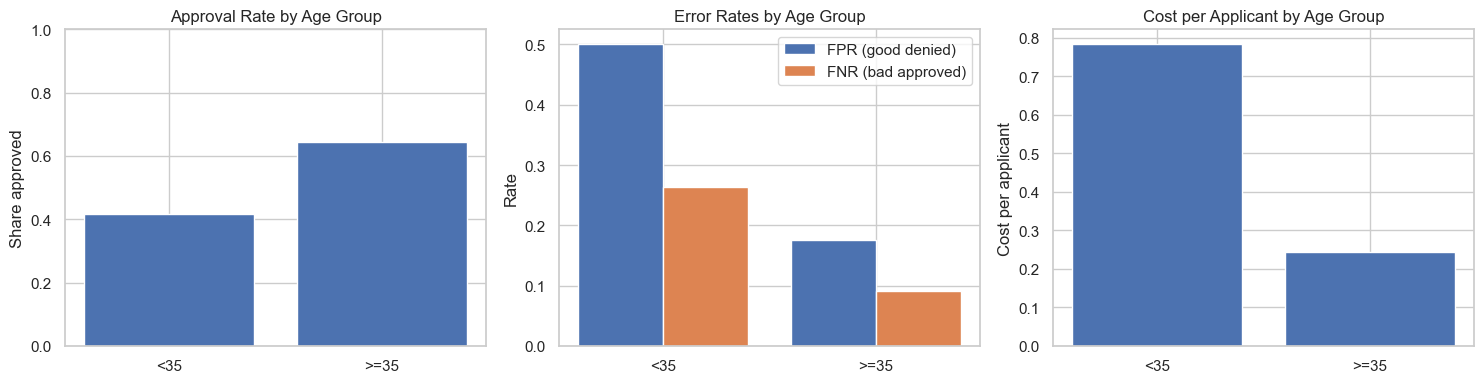

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

groups = group_results.index

axes[0].bar(groups, group_results["Approval rate"])
axes[0].set_title("Approval Rate by Age Group")
axes[0].set_ylabel("Share approved")
axes[0].set_ylim(0, 1)

x = np.arange(len(groups))
axes[1].bar(x - 0.2, group_results["FPR (good denied)"], width=0.4, label="FPR (good denied)")
axes[1].bar(x + 0.2, group_results["FNR (bad approved)"], width=0.4, label="FNR (bad approved)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(groups)
axes[1].set_title("Error Rates by Age Group")
axes[1].set_ylabel("Rate")
axes[1].legend()

axes[2].bar(groups, group_results["Cost per applicant"])
axes[2].set_title("Cost per Applicant by Age Group")
axes[2].set_ylabel("Cost per applicant")

plt.tight_layout()
plt.show()

In [51]:
group_results.to_pickle("saved_files/group_results_baseline.pkl")
print("Saved group results")

Saved group results


In [53]:
""" the AGE_model is completed, upcomming things are optional (for better comparision)"""

' the AGE_model is completed, upcomming things are optional (for better comparision)'

In [54]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split

# Rebuild X, y and age group from the saved dataframe
X = df[numeric_features + categorical_features]
y = df["bad_credit"]
age_group = df["age_group"]
strat_label = y.astype(str) + "_" + age_group

thresholds = np.arange(0.05, 0.95, 0.01)
results = []

for seed in range(100):
    # Same 80/10/10 split as before, but with a different seed
    X_tr, X_tmp, y_tr, y_tmp, a_tr, a_tmp, s_tr, s_tmp = train_test_split(
        X, y, age_group, strat_label, test_size=0.20,
        stratify=strat_label, random_state=seed)
    X_va, X_te, y_va, y_te, a_va, a_te = train_test_split(
        X_tmp, y_tmp, a_tmp, test_size=0.50,
        stratify=s_tmp, random_state=seed)

    # Fresh copy of the baseline pipeline, trained on this training set
    model = clone(baseline_model)
    model.fit(X_tr, y_tr)

    # Choose the cost-minimizing threshold on validation only
    p_va = model.predict_proba(X_va)[:, 1]
    costs = [total_cost(y_va, (p_va >= t).astype(int)) for t in thresholds]
    t_best = thresholds[np.argmin(costs)]

    # Apply it to the test set
    p_te = model.predict_proba(X_te)[:, 1]
    pred = (p_te >= t_best).astype(int)

    # Metrics per age group
    row = {"seed": seed, "threshold": round(t_best, 2),
           "total_cost": total_cost(y_te, pred)}
    for g, name in [("<35", "young"), (">=35", "old")]:
        mask = (a_te == g).values
        tn, fp, fn, tp = confusion_matrix(y_te.values[mask], pred[mask], labels=[0, 1]).ravel()
        row["FPR_" + name] = fp / (fp + tn)
        row["FNR_" + name] = fn / (fn + tp)
        row["approval_" + name] = (pred[mask] == 0).mean()
    results.append(row)

repeat_results = pd.DataFrame(results)
repeat_results["FPR_gap"] = repeat_results["FPR_young"] - repeat_results["FPR_old"]
repeat_results["FNR_gap"] = repeat_results["FNR_young"] - repeat_results["FNR_old"]
repeat_results["approval_gap"] = repeat_results["approval_young"] - repeat_results["approval_old"]

joblib.dump(repeat_results, "saved_files/repeat_results.joblib")
display(repeat_results.head())

,seed,threshold,total_cost,FPR_young,FNR_young,approval_young,FPR_old,FNR_old,approval_old,FPR_gap,FNR_gap,approval_gap
0,0,0.21,47,0.472222,0.105263,0.381818,0.294118,0.181818,0.577778,0.178105,-0.076555,-0.195960
1,1,0.09,53,0.771429,0.052632,0.166667,0.600000,0.000000,0.304348,0.171429,0.052632,-0.137681
2,2,0.11,49,0.638889,0.105263,0.272727,0.470588,0.000000,0.400000,0.168301,0.105263,-0.127273
3,3,0.27,66,0.388889,0.368421,0.527273,0.352941,0.090909,0.511111,0.035948,0.277512,0.016162
4,4,0.21,67,0.555556,0.157895,0.345455,0.352941,0.363636,0.577778,0.202614,-0.205742,-0.232323


In [55]:
cols = ["total_cost", "threshold", "FPR_gap", "FNR_gap", "approval_gap"]
summary = repeat_results[cols].agg(
    ["mean", "std", lambda s: s.quantile(0.025), lambda s: s.quantile(0.975)]).round(3)
summary.index = ["mean", "std", "2.5% quantile", "97.5% quantile"]
display(summary)

print("Share of seeds where young applicants have a higher FPR:",
      (repeat_results["FPR_gap"] > 0).mean())
print("Share of seeds where young applicants have a higher FNR:",
      (repeat_results["FNR_gap"] > 0).mean())

,total_cost,threshold,FPR_gap,FNR_gap,approval_gap
mean,54.930,0.157,0.126,-0.017,-0.132
std,9.927,0.063,0.124,0.141,0.094
2.5% quantile,35.950,0.060,-0.101,-0.273,-0.303
97.5% quantile,74.000,0.290,0.354,0.271,0.028


Share of seeds where young applicants have a higher FPR: 0.81
Share of seeds where young applicants have a higher FNR: 0.43


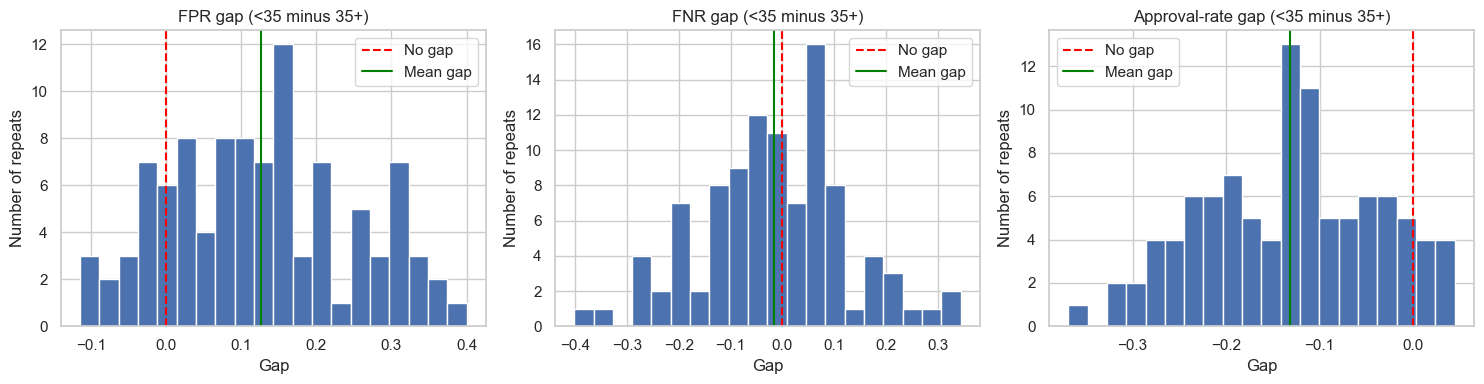

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col, title in zip(
    axes,
    ["FPR_gap", "FNR_gap", "approval_gap"],
    ["FPR gap (<35 minus 35+)", "FNR gap (<35 minus 35+)", "Approval-rate gap (<35 minus 35+)"]):
    ax.hist(repeat_results[col], bins=20)
    ax.axvline(0, color="red", linestyle="--", label="No gap")
    ax.axvline(repeat_results[col].mean(), color="green", linestyle="-", label="Mean gap")
    ax.set_title(title)
    ax.set_xlabel("Gap")
    ax.set_ylabel("Number of repeats")
    ax.legend()

plt.tight_layout()
plt.show()

In [57]:
"""Fairness Intervention (Group-Specific Thresholds)"""

'Fairness Intervention (Group-Specific Thresholds)'

In [58]:
thresholds = np.arange(0.05, 0.95, 0.01)

def counts_for_thresholds(y, p):
    """For every threshold: false positives, false negatives, number of good and bad."""
    y = np.asarray(y)
    pred = (p[:, None] >= thresholds[None, :])        # rows = people, columns = thresholds
    fp = (pred & (y == 0)[:, None]).sum(axis=0)       # good but denied
    fn = (~pred & (y == 1)[:, None]).sum(axis=0)      # bad but approved
    return fp, fn, (y == 0).sum(), (y == 1).sum()

def choose_group_thresholds(y_val, p_val, a_val, max_gap=0.05):
    """Pick (t_young, t_old) with the lowest cost, keeping the FPR gap small."""
    young = (a_val == "<35").values
    old = (a_val == ">=35").values

    fp_y, fn_y, good_y, _ = counts_for_thresholds(y_val.values[young], p_val[young])
    fp_o, fn_o, good_o, _ = counts_for_thresholds(y_val.values[old], p_val[old])

    fpr_y = fp_y / good_y
    fpr_o = fp_o / good_o
    cost_y = 5 * fn_y + fp_y
    cost_o = 5 * fn_o + fp_o

    gap = np.abs(fpr_y[:, None] - fpr_o[None, :])     # all pairs of thresholds
    cost = cost_y[:, None] + cost_o[None, :]

    cost_ok = np.where(gap <= max_gap, cost, np.inf)  # only keep pairs with a small gap
    if np.isinf(cost_ok).all():                       # safety: if none qualifies, use smallest gap
        i, j = np.unravel_index(np.argmin(gap), gap.shape)
    else:
        i, j = np.unravel_index(np.argmin(cost_ok), cost_ok.shape)
    return round(thresholds[i], 2), round(thresholds[j], 2)

def apply_group_thresholds(p, ages, t_young, t_old):
    ages = np.asarray(ages)
    return np.where(ages == "<35", p >= t_young, p >= t_old).astype(int)

def group_metrics(y, pred, ages):
    """FPR, FNR and approval rate for each age group."""
    out = {}
    for g, name in [("<35", "young"), (">=35", "old")]:
        mask = (np.asarray(ages) == g)
        tn, fp, fn, tp = confusion_matrix(np.asarray(y)[mask], pred[mask], labels=[0, 1]).ravel()
        out["FPR_" + name] = fp / (fp + tn)
        out["FNR_" + name] = fn / (fn + tp)
        out["approval_" + name] = (pred[mask] == 0).mean()
    return out

print("Helper functions ready")

Helper functions ready


In [59]:
t_young, t_old = choose_group_thresholds(y_val, val_probs, age_val)
print("Threshold for <35: ", t_young)
print("Threshold for 35+: ", t_old)
print("(Baseline used one threshold for everyone:", threshold, ")")

# Validation check: baseline vs new thresholds
val_pred_base = (val_probs >= threshold).astype(int)
val_pred_new = apply_group_thresholds(val_probs, age_val, t_young, t_old)

val_compare = pd.DataFrame({
    "Baseline": {**group_metrics(y_val, val_pred_base, age_val), "cost": total_cost(y_val, val_pred_base)},
    "Group thresholds": {**group_metrics(y_val, val_pred_new, age_val), "cost": total_cost(y_val, val_pred_new)}
}).round(3)
display(val_compare)

Threshold for <35:  0.19
Threshold for 35+:  0.09
(Baseline used one threshold for everyone: 0.21 )


,Baseline,Group thresholds
FPR_young,0.571,0.571
FNR_young,0.158,0.158
approval_young,0.333,0.333
FPR_old,0.429,0.571
FNR_old,0.091,0.000
approval_old,0.457,0.326
cost,55.000,55.000


In [60]:
test_pred_new = apply_group_thresholds(test_probs, age_test, t_young, t_old)

base = group_metrics(y_test, test_pred, age_test)
new = group_metrics(y_test, test_pred_new, age_test)

for d in (base, new):
    d["FPR_gap"] = d["FPR_young"] - d["FPR_old"]
    d["FNR_gap"] = d["FNR_young"] - d["FNR_old"]
    d["approval_gap"] = d["approval_young"] - d["approval_old"]

base["total_cost"] = total_cost(y_test, test_pred)
new["total_cost"] = total_cost(y_test, test_pred_new)
base["accuracy"] = accuracy_score(y_test, test_pred)
new["accuracy"] = accuracy_score(y_test, test_pred_new)

test_compare = pd.DataFrame({"Baseline": base, "Group thresholds": new}).round(3)
display(test_compare)

,Baseline,Group thresholds
FPR_young,0.500,0.556
FNR_young,0.263,0.211
approval_young,0.418,0.364
FPR_old,0.176,0.441
FNR_old,0.091,0.091
approval_old,0.644,0.444
FPR_gap,0.324,0.114
FNR_gap,0.172,0.120
approval_gap,-0.226,-0.081
total_cost,54.000,60.000


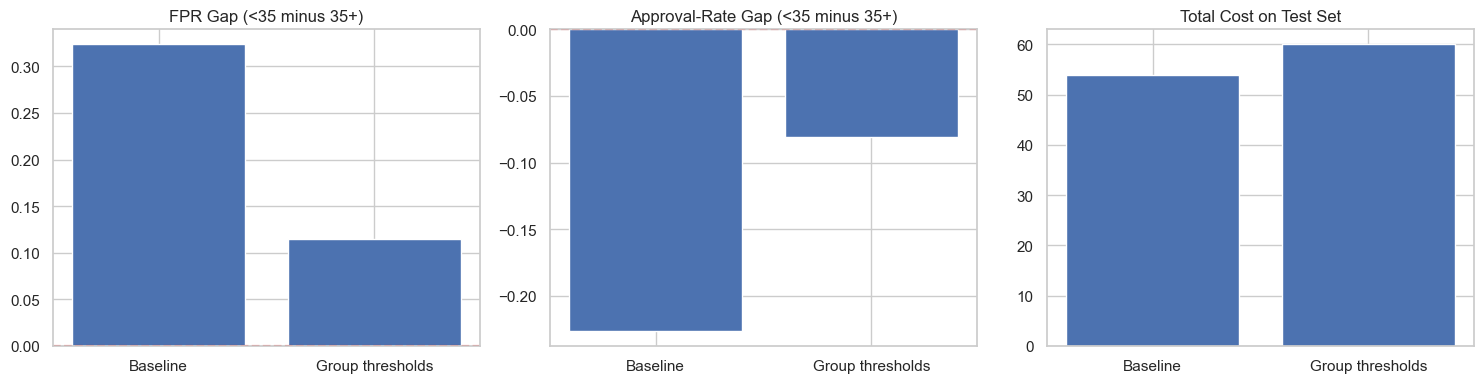

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
labels = ["Baseline", "Group thresholds"]

axes[0].bar(labels, [base["FPR_gap"], new["FPR_gap"]])
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("FPR Gap (<35 minus 35+)")

axes[1].bar(labels, [base["approval_gap"], new["approval_gap"]])
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Approval-Rate Gap (<35 minus 35+)")

axes[2].bar(labels, [base["total_cost"], new["total_cost"]])
axes[2].set_title("Total Cost on Test Set")

plt.tight_layout()
plt.show()

In [62]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split

X = df[numeric_features + categorical_features]
y = df["bad_credit"]
age_group = df["age_group"]
strat_label = y.astype(str) + "_" + age_group

new_results = []
for seed in range(100):
    X_tr, X_tmp, y_tr, y_tmp, a_tr, a_tmp, s_tr, s_tmp = train_test_split(
        X, y, age_group, strat_label, test_size=0.20, stratify=strat_label, random_state=seed)
    X_va, X_te, y_va, y_te, a_va, a_te = train_test_split(
        X_tmp, y_tmp, a_tmp, test_size=0.50, stratify=s_tmp, random_state=seed)

    model = clone(baseline_model)
    model.fit(X_tr, y_tr)
    p_va = model.predict_proba(X_va)[:, 1]
    p_te = model.predict_proba(X_te)[:, 1]

    ty, to = choose_group_thresholds(y_va, p_va, a_va)
    pred = apply_group_thresholds(p_te, a_te, ty, to)

    row = {"seed": seed, "t_young": ty, "t_old": to, "total_cost": total_cost(y_te, pred)}
    row.update(group_metrics(y_te, pred, a_te))
    new_results.append(row)

new_results = pd.DataFrame(new_results)
new_results["FPR_gap"] = new_results["FPR_young"] - new_results["FPR_old"]
new_results["FNR_gap"] = new_results["FNR_young"] - new_results["FNR_old"]
new_results["approval_gap"] = new_results["approval_young"] - new_results["approval_old"]

joblib.dump(new_results, "saved_files/intervention_results.joblib")
print("Done")

Done


In [63]:
cols = ["total_cost", "FPR_gap", "FNR_gap", "approval_gap"]

comparison = pd.DataFrame({
    "Baseline mean": repeat_results[cols].mean(),
    "Baseline std": repeat_results[cols].std(),
    "Group-threshold mean": new_results[cols].mean(),
    "Group-threshold std": new_results[cols].std()
}).round(3)
display(comparison)

print("Average threshold, <35:", round(new_results["t_young"].mean(), 3))
print("Average threshold, 35+:", round(new_results["t_old"].mean(), 3))
print("Share of seeds where young still have higher FPR:", (new_results["FPR_gap"] > 0).mean())

,Baseline mean,Baseline std,Group-threshold mean,Group-threshold std
total_cost,54.930,9.927,57.140,10.152
FPR_gap,0.126,0.124,0.041,0.138
FNR_gap,-0.017,0.141,0.031,0.155
approval_gap,-0.132,0.094,-0.057,0.111


Average threshold, <35: 0.18
Average threshold, 35+: 0.14
Share of seeds where young still have higher FPR: 0.61


/var/folders/zp/bmr2z42j0v19n5r231_h7gfh0000gn/T/ipykernel_53886/928037128.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([repeat_results[col], new_results[col]], labels=["Baseline", "Group thresholds"])
/var/folders/zp/bmr2z42j0v19n5r231_h7gfh0000gn/T/ipykernel_53886/928037128.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([repeat_results[col], new_results[col]], labels=["Baseline", "Group thresholds"])
/var/folders/zp/bmr2z42j0v19n5r231_h7gfh0000gn/T/ipykernel_53886/928037128.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([repeat_results[col], new_results[col]], labels

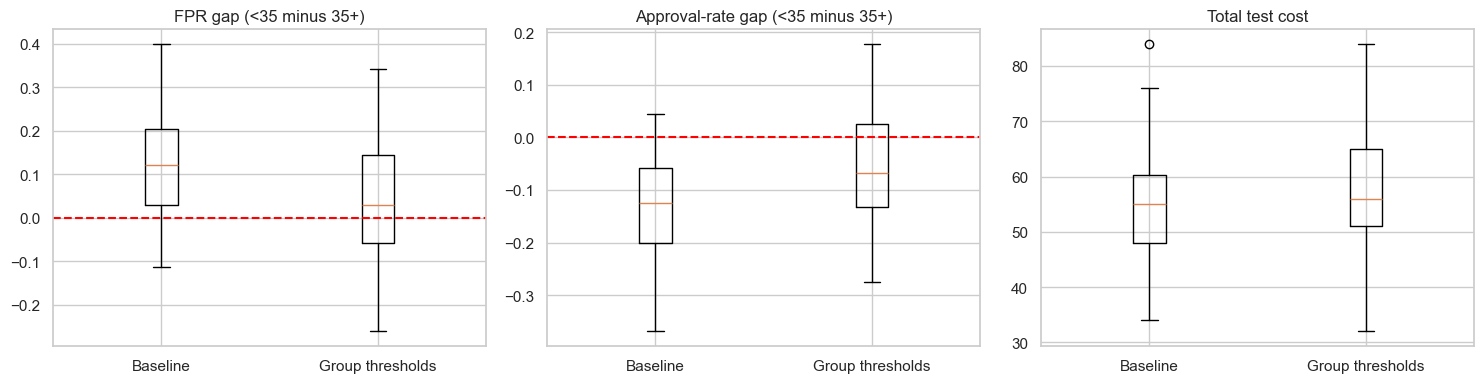

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col, title in zip(axes, ["FPR_gap", "approval_gap", "total_cost"],
                          ["FPR gap (<35 minus 35+)", "Approval-rate gap (<35 minus 35+)", "Total test cost"]):
    ax.boxplot([repeat_results[col], new_results[col]], labels=["Baseline", "Group thresholds"])
    if col != "total_cost":
        ax.axhline(0, color="red", linestyle="--")
    ax.set_title(title)

plt.tight_layout()
plt.show()

In [65]:
joblib.dump({"t_young": t_young, "t_old": t_old}, "saved_files/group_thresholds.joblib")
print("Saved group thresholds")

Saved group thresholds


In [70]:
# Original codes: A91 male divorced/separated, A92 female divorced/separated/married,
# A93 male single, A94 male married/widowed, A95 female single
df["personal_label"] = df["personal_status_sex"].map({
    "A91": "male: divorced/separated",
    "A92": "female: divorced/sep/married",
    "A93": "male: single",
    "A94": "male: married/widowed",
    "A95": "female: single"
})

summary = df.groupby("personal_label")["bad_credit"].agg(["count", "sum", "mean"])
summary.columns = ["applicants", "bad_credits", "bad_rate"]
summary["bad_rate"] = (summary["bad_rate"] * 100).round(1)
display(summary)

,applicants,bad_credits,bad_rate
personal_label,,,
female: divorced/sep/married,310,109,35.2
male: divorced/separated,50,20,40.0
male: married/widowed,92,25,27.2
male: single,548,146,26.6


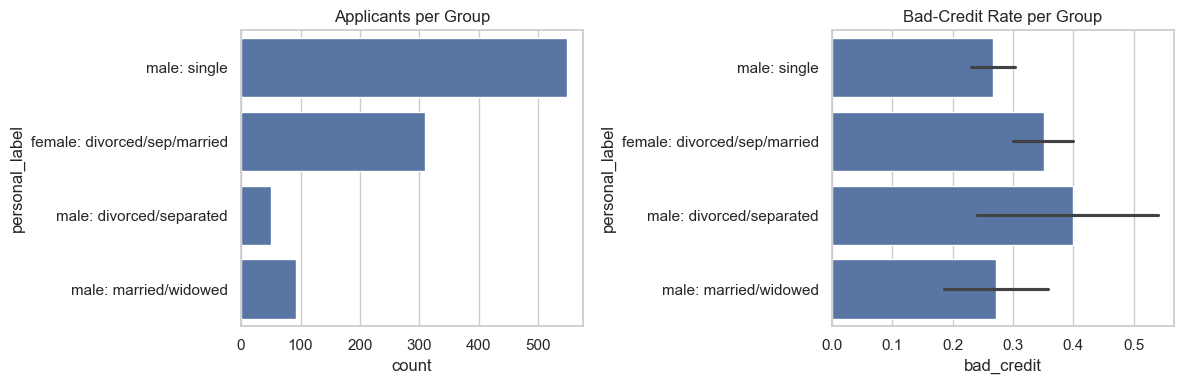

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(y="personal_label", data=df, ax=axes[0])
axes[0].set_title("Applicants per Group")

sns.barplot(y="personal_label", x="bad_credit", data=df, ax=axes[1])
axes[1].set_title("Bad-Credit Rate per Group")

plt.tight_layout()
plt.show()

In [72]:
df["sex_group"] = np.where(df["personal_status_sex"] == "A92", "female", "male")
print(df["sex_group"].value_counts())
print(df.groupby("sex_group")["bad_credit"].mean().round(3))

sex_group
male      690
female    310
Name: count, dtype: int64
sex_group
female    0.352
male      0.277
Name: bad_credit, dtype: float64


In [73]:
cat_no_ps = [c for c in categorical_features if c != "personal_status_sex"]

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

prep_sex = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_no_ps)
])
sex_model = Pipeline([
    ("preprocessor", prep_sex),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# Use the SAME rows as the age model (same split), so results are comparable
sex_train = df.loc[X_train.index, "sex_group"]
sex_val = df.loc[X_val.index, "sex_group"]
sex_test = df.loc[X_test.index, "sex_group"]

sex_model.fit(X_train[numeric_features + cat_no_ps], y_train)
val_p = sex_model.predict_proba(X_val[numeric_features + cat_no_ps])[:, 1]

thr = np.arange(0.05, 0.95, 0.01)
costs = [total_cost(y_val, (val_p >= t).astype(int)) for t in thr]
sex_threshold = round(thr[np.argmin(costs)], 2)
print("Threshold chosen on validation:", sex_threshold, "| cost:", min(costs))

Threshold chosen on validation: 0.09 | cost: 55


In [74]:
test_p = sex_model.predict_proba(X_test[numeric_features + cat_no_ps])[:, 1]
test_pred_sex = (test_p >= sex_threshold).astype(int)

rows = []
for g in ["female", "male"]:
    mask = (sex_test == g).values
    tn, fp, fn, tp = confusion_matrix(y_test.values[mask], test_pred_sex[mask], labels=[0, 1]).ravel()
    rows.append({
        "Group": g, "Applicants": mask.sum(), "Actual bad": (fn + tp),
        "Approval rate": round((test_pred_sex[mask] == 0).mean(), 3),
        "FPR (good denied)": round(fp / (fp + tn), 3),
        "FNR (bad approved)": round(fn / (fn + tp), 3),
        "Cost per applicant": round((5 * fn + fp) / mask.sum(), 3)
    })
display(pd.DataFrame(rows).set_index("Group"))
print("Overall test cost:", total_cost(y_test, test_pred_sex))

,Applicants,Actual bad,Approval rate,FPR (good denied),FNR (bad approved),Cost per applicant
Group,,,,,,
female,26,10,0.385,0.438,0.10,0.462
male,74,20,0.297,0.611,0.05,0.514


Overall test cost: 50


In [75]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split

Xs = df[numeric_features + cat_no_ps]
sg = df["sex_group"]
strat = y.astype(str) + "_" + sg

res = []
for seed in range(100):
    Xtr, Xtmp, ytr, ytmp, gtr, gtmp, s1, s2 = train_test_split(
        Xs, y, sg, strat, test_size=0.20, stratify=strat, random_state=seed)
    Xva, Xte, yva, yte, gva, gte = train_test_split(
        Xtmp, ytmp, gtmp, test_size=0.50, stratify=s2, random_state=seed)
    m = clone(sex_model).fit(Xtr, ytr)
    pv = m.predict_proba(Xva)[:, 1]
    t = thr[np.argmin([total_cost(yva, (pv >= x).astype(int)) for x in thr])]
    pred = (m.predict_proba(Xte)[:, 1] >= t).astype(int)
    row = {"seed": seed, "total_cost": total_cost(yte, pred)}
    for g in ["female", "male"]:
        mk = (gte == g).values
        tn, fp, fn, tp = confusion_matrix(yte.values[mk], pred[mk], labels=[0, 1]).ravel()
        row["FPR_" + g] = fp / (fp + tn)
        row["FNR_" + g] = fn / (fn + tp)
        row["appr_" + g] = (pred[mk] == 0).mean()
    res.append(row)

sex_res = pd.DataFrame(res)
sex_res["FPR_gap"] = sex_res["FPR_female"] - sex_res["FPR_male"]
sex_res["FNR_gap"] = sex_res["FNR_female"] - sex_res["FNR_male"]
sex_res["approval_gap"] = sex_res["appr_female"] - sex_res["appr_male"]

summary_sex = sex_res[["total_cost", "FPR_gap", "FNR_gap", "approval_gap"]].agg(
    ["mean", "std", lambda s: s.quantile(0.025), lambda s: s.quantile(0.975)]).round(3)
summary_sex.index = ["mean", "std", "2.5% quantile", "97.5% quantile"]
display(summary_sex)
print("Share of seeds where women have higher FPR:", (sex_res["FPR_gap"] > 0).mean())

,total_cost,FPR_gap,FNR_gap,approval_gap
mean,57.280,-0.025,-0.024,-0.018
std,10.834,0.127,0.112,0.096
2.5% quantile,41.475,-0.282,-0.211,-0.187
97.5% quantile,81.525,0.220,0.240,0.176


Share of seeds where women have higher FPR: 0.39


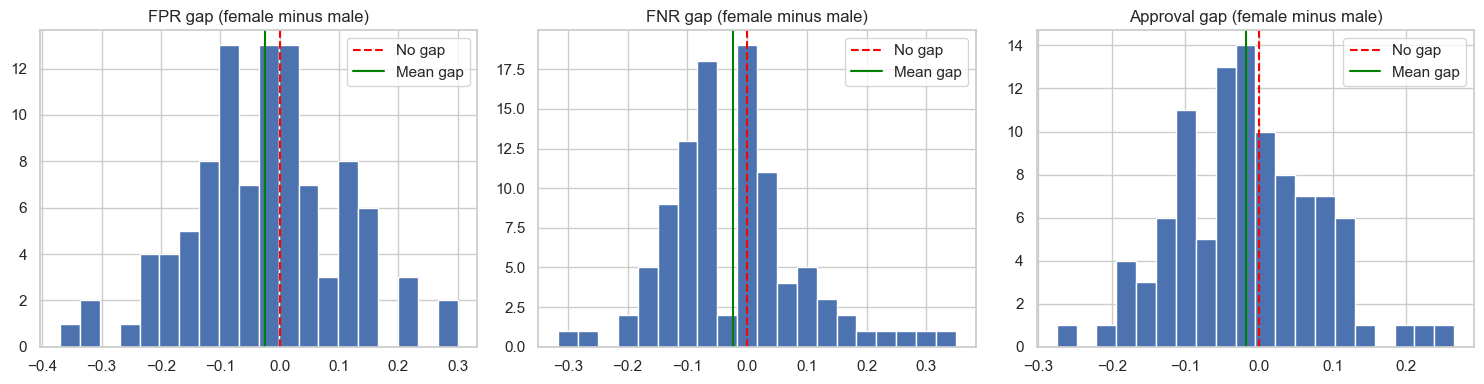

In [76]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in zip(axes, ["FPR_gap", "FNR_gap", "approval_gap"],
        ["FPR gap (female minus male)", "FNR gap (female minus male)", "Approval gap (female minus male)"]):
    ax.hist(sex_res[col], bins=20)
    ax.axvline(0, color="red", linestyle="--", label="No gap")
    ax.axvline(sex_res[col].mean(), color="green", label="Mean gap")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()